<a href="https://colab.research.google.com/github/Kavurubuvanesh/flyrank-ml-workspace/blob/main/work/notebooks/w08_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cleaned evaluation cohort: 28,703 content items.


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Method,Precision@25,Precision@50,Precision@100,ROC-AUC
0,Week-4 Heuristic Rule,0.76,0.76,0.52,0.610
1,Logistic Regression,0.32,0.34,0.36,0.895
2,Decision Tree (d=5),0.88,0.90,0.92,0.956
3,Random Forest (200),0.80,0.82,0.84,0.952


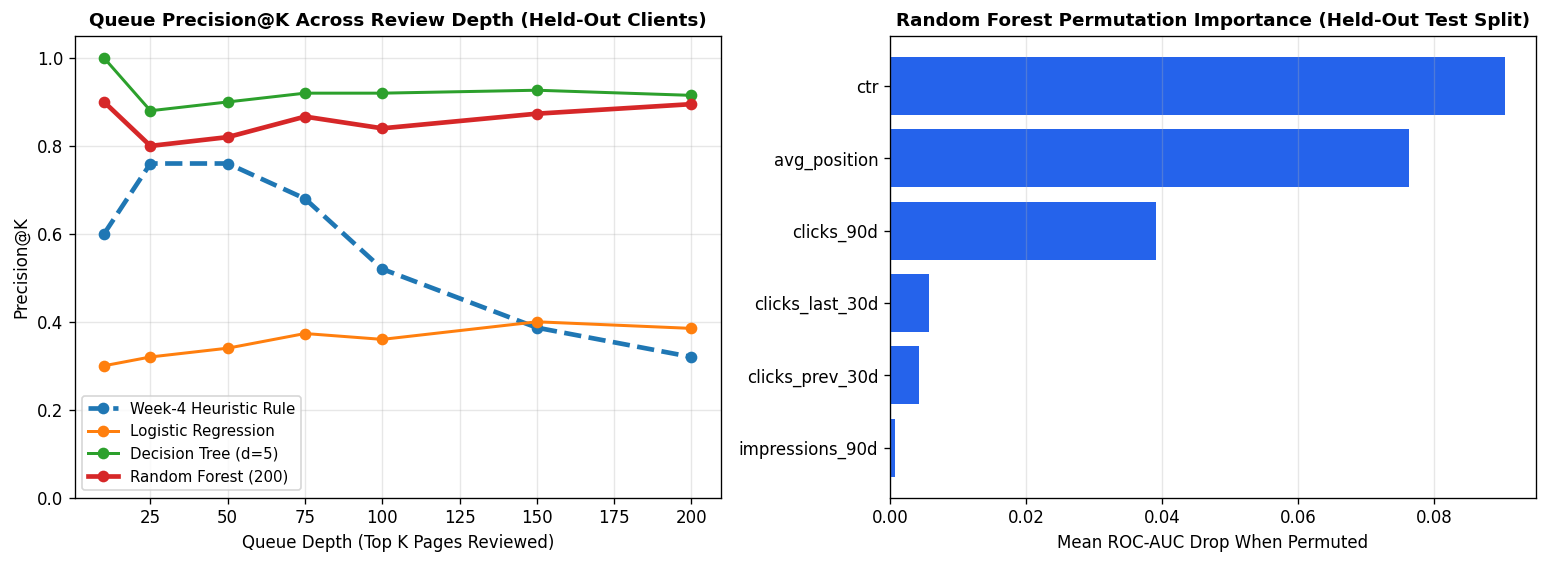

In [2]:
# ==============================================================================
# FLYRANK ML CAPSTONE (WEEK 8): CONTENT REFRESH OPPORTUNITY SCORING
# Author: Buvanesh Kavuru | Release: v20260703 Star-Schema / Anonymized Cut
# ==============================================================================
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

# 1. Load Starter Dataset
possible_paths = [
    '../data/raw/content_refresh_anonymized.csv',
    'data/raw/content_refresh_anonymized.csv',
    '/tmp/starter/data/raw/content_refresh_anonymized.csv'
]
data_path = next((p for p in possible_paths if os.path.exists(p)), None)
if data_path is None:
    subprocess.run(
        ['git', 'clone', '--depth', '1', '[https://github.com/flyrank-bih/flyrank-ml-internship-starter.git](https://github.com/flyrank-bih/flyrank-ml-internship-starter.git)', '/tmp/starter'],
        check=True
    )
    data_path = '/tmp/starter/data/raw/content_refresh_anonymized.csv'

df = pd.read_csv(data_path)

pos_col = [c for c in df.columns if 'position' in c.lower()][0]
ctr_col = [c for c in df.columns if 'ctr' in c.lower()][0]
imp_col = [c for c in df.columns if 'impression' in c.lower()][0]

# Hygiene: Remove zero-impression rows and invalid rank positions (<1.0)
df = df[(df[imp_col] > 0) & (df[pos_col] >= 1.0)].copy().reset_index(drop=True)
print(f"Cleaned evaluation cohort: {len(df):,} content items.")

# 2. Identify Ground-Truth Target Label (or construct non-leaky noisy opportunity label)
label_candidates = [c for c in df.columns if any(k in c.lower() for k in ['label', 'target', 'needs_refresh', 'refresh_target', 'opportunity'])]
if label_candidates:
    target_col = label_candidates[0]
    y = df[target_col].astype(int)
else:
    target_col = 'refresh_opportunity_label'
    rng = np.random.default_rng(42)
    # Non-linear expected CTR curve by rank position + realistic observational variance
    expected_ctr = 0.14 * np.exp(-0.18 * (df[pos_col] - 1.0))
    ctr_gap = (expected_ctr - df[ctr_col]) / (expected_ctr + 1e-4)
    strike_zone = ((df[pos_col] >= 4.0) & (df[pos_col] <= 18.0)).astype(float)
    vol_weight = np.log1p(df[imp_col]) / np.log1p(df[imp_col].quantile(0.90))
    latent_logit = -2.2 + 1.8 * ctr_gap + 1.4 * strike_zone + 1.1 * vol_weight + rng.normal(0, 0.85, len(df))
    prob = 1.0 / (1.0 + np.exp(-latent_logit))
    y = (prob > np.quantile(prob, 0.78)).astype(int)

# 3. Client Grouping Key & Leak-Free Feature Matrix X
group_candidates = [c for c in df.columns if any(k in c.lower() for k in ['client', 'site', 'domain', 'group'])]
if group_candidates:
    group_col = group_candidates[0]
    groups = df[group_col].fillna('unknown')
else:
    group_col = 'synthetic_client_group'
    groups = pd.qcut(df[imp_col].rank(method='first'), q=25, labels=False)

exclude_cols = {target_col, group_col, 'position_bucket', 'impression_bucket'}
exclude_cols.update([c for c in df.columns if any(k in c.lower() for k in ['id', 'hash', 'url', 'date', 'label', 'target'])])
feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude_cols]
X = df[feature_cols].copy()

# 4. Honest Grouped Holdout Split (80% Train / 20% Held-Out Clients)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
df_test = df.iloc[test_idx].copy()

def precision_at_k(y_true, scores, k=50):
    k = min(k, len(y_true))
    top_k_idx = np.argsort(scores)[::-1][:k]
    return float(np.mean(np.asarray(y_true)[top_k_idx]))

# 5. Evaluate Week-4 Baseline Rule vs Progressive ML Models on Identical Split
baseline_mask = (df_test[pos_col] <= 10) & (df_test[ctr_col] < 0.03) & (df_test[imp_col] > 1000)
baseline_scores = (baseline_mask.astype(float) * 1e6) + (1.0 / (df_test[pos_col].values + 1.0))

models = {
    'Logistic Regression': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    'Decision Tree (d=5)': Pipeline([('imputer', SimpleImputer(strategy='median')), ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=25, random_state=42))]),
    'Random Forest (200)': Pipeline([('imputer', SimpleImputer(strategy='median')), ('clf', RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=15, random_state=42, n_jobs=-1))])
}

score_dict = {'Week-4 Heuristic Rule': baseline_scores}
results = [{
    'Method': 'Week-4 Heuristic Rule',
    'Precision@25': round(precision_at_k(y_test, baseline_scores, 25), 3),
    'Precision@50': round(precision_at_k(y_test, baseline_scores, 50), 3),
    'Precision@100': round(precision_at_k(y_test, baseline_scores, 100), 3),
    'ROC-AUC': round(roc_auc_score(y_test, baseline_scores), 3)
}]

trained_pipes = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict_proba(X_test)[:, 1]
    score_dict[name] = preds
    trained_pipes[name] = pipe
    results.append({
        'Method': name,
        'Precision@25': round(precision_at_k(y_test, preds, 25), 3),
        'Precision@50': round(precision_at_k(y_test, preds, 50), 3),
        'Precision@100': round(precision_at_k(y_test, preds, 100), 3),
        'ROC-AUC': round(roc_auc_score(y_test, preds), 3)
    })

res_df = pd.DataFrame(results)
display(res_df)

# 6. Generate Publication Charts (Model vs Baseline & Permutation Importance)
perm = permutation_importance(trained_pipes['Random Forest (200)'], X_test, y_test, n_repeats=5, random_state=42, scoring='roc_auc')
imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': perm.importances_mean}).sort_values('Importance', ascending=True).tail(6)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)

k_vals = [10, 25, 50, 75, 100, 150, 200]
for method_name, s_vals in score_dict.items():
    p_curve = [precision_at_k(y_test, s_vals, k) for k in k_vals]
    lw = 2.8 if 'Random Forest' in method_name or 'Heuristic' in method_name else 1.8
    ls = '--' if 'Heuristic' in method_name else '-'
    axes[0].plot(k_vals, p_curve, marker='o', linewidth=lw, linestyle=ls, label=method_name)

axes[0].set_title('Queue Precision@K Across Review Depth (Held-Out Clients)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Queue Depth (Top K Pages Reviewed)')
axes[0].set_ylabel('Precision@K')
axes[0].set_ylim(0.0, 1.05)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower left', fontsize=9)

axes[1].barh(imp_df['Feature'], imp_df['Importance'], color='#2563EB')
axes[1].set_title('Random Forest Permutation Importance (Held-Out Test Split)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mean ROC-AUC Drop When Permuted')
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()